In [2]:
using QuantumOptics, Plots

# JC setup (task 1)

In [3]:
nf = 12; # cutoff Fock Space
g = 1; # coupling
ħ = 1; 
δ = 0.1; # detuning: ωₐ-ωc
ωc = 25;

nt = 128;  tf = 12 ; T = LinRange(0,tf,nt); # time steps

basis_fock = FockBasis(nf);
basis_atom = SpinBasis(1//2);

basis_jc = basis_fock ⊗ basis_atom; # basis for JC system

a = destroy(basis_fock) ⊗ one(basis_atom);
a⁺ = dagger(a);

σ = one(basis_fock) ⊗ sigmam(basis_atom);
σ⁺ = dagger(σ);

H = ħ*ωc* a⁺*a + ħ*(ωc + δ)*σ⁺*σ +  ħ*g*(a*σ⁺ + a⁺*σ);                          # Hamiltonian  JC

In [4]:
K = 1/4; # dampening
γ=1/8;
J=[sqrt(K)*a, sqrt(γ)*σ]; # decay operator
δ=0; H0 = ħ*δ* a⁺*a + ħ*g*(a*σ⁺ + a⁺*σ); # resonant case ωa-ωc=δ=0

In [5]:
C = g^2/(K*γ) # check coupling strangth: C > 1

32.0

# Task 2

## define initial states with a fixed photon number n = (0, 1, 2, 3) and the atom in the ground state. 

In [6]:
ρ0 = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); # |n=0, g> 
ρ1 = dm(basisstate(basis_fock, 2)⊗basisstate(basis_atom, 2)); # |n=1, g> 
ρ2 = dm(basisstate(basis_fock, 3)⊗basisstate(basis_atom, 2)); # |n=2, g> 
ρ3 = dm(basisstate(basis_fock, 4)⊗basisstate(basis_atom, 2)); # |n=3, g> 

t0, ρ0t = timeevolution.master(2T, ρ0, H0, J);
t1, ρ1t = timeevolution.master(2T, ρ1, H0, J);
t2, ρ2t = timeevolution.master(2T, ρ2, H0, J);
t3, ρ3t = timeevolution.master(2T, ρ3, H0, J);

## solve the corresponding master equation and compare the time evolution of photon number and atomic upper state population

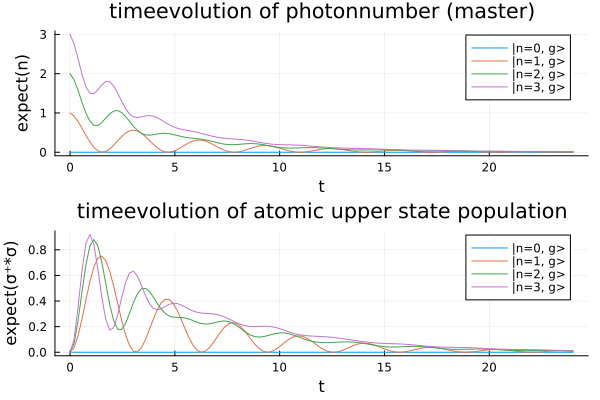

In [7]:
pl_1 = plot(xlabel="t", ylabel="expect(n)", title="timeevolution of photonnumber (master)");

pl_1 = plot!(t0, real.(expect(a⁺*a, ρ0t)), label="|n=0, g>"); pl_1 = plot!(t1, real.(expect(a⁺*a, ρ1t)), label="|n=1, g>"); pl_1 = plot!(t2, real.(expect(a⁺*a, ρ2t)), label="|n=2, g>");
pl_1 = plot!(t3, real.(expect(a⁺*a, ρ3t)), label="|n=3, g>");

pl_2 = plot(xlabel="t", ylabel="expect(σ⁺*σ)", title="timeevolution of atomic upper state population");

pl_2 = plot!(t0, real.(expect(σ⁺*σ, ρ0t)), label="|n=0, g>"); pl_2 = plot!(t1, real.(expect(σ⁺*σ, ρ1t)), label="|n=1, g>"); pl_2 = plot!(t2, real.(expect(σ⁺*σ, ρ2t)), label="|n=2, g>");
pl_2 = plot!(t3, real.(expect(σ⁺*σ, ρ3t)), label="|n=3, g>");

plot(pl_1, pl_2, layout=(2,1))

## solution from lecture

In [8]:
ρ_0=dm(basisstate(basis_fock,1)⊗basisstate(basis_atom,1)); t,ρt   = timeevolution.master(2T,ρ_0,H0,J);   # atom excited: |n=0, e>
ρ_1=dm(basisstate(basis_fock,2)⊗basisstate(basis_atom,2)); t1,ρt1   = timeevolution.master(2T,ρ_1,H0,J); # 1 photon: |n=1, g>
ρ_2=dm(basisstate(basis_fock,2)⊗basisstate(basis_atom,1)); t2,ρt2   = timeevolution.master(2T,ρ_2,H0,J); # excited, 1 photon: |n=1, e>

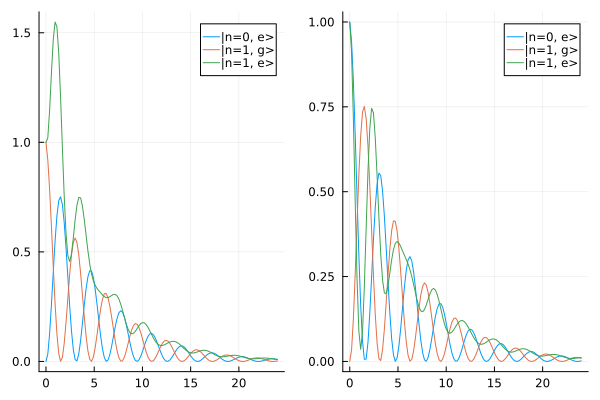

In [9]:
pl_1 = plot(t, real.(expect(a⁺*a, ρt)), label="|n=0, e>"); pl_1 = plot!(t1, real.(expect(a⁺*a, ρt1)), label="|n=1, g>"); pl_1 = plot!(t2, real.(expect(a⁺*a, ρt2)), label="|n=1, e>");
pl_2 = plot(t, real.(expect(σ⁺*σ, ρt)), label="|n=0, e>"); pl_2 = plot!(t1, real.(expect(σ⁺*σ, ρt1)), label="|n=1, g>"); pl_2 = plot!(t2, real.(expect(σ⁺*σ, ρt2)), label="|n=1, e>");
plot(pl_1, pl_2,)

# Task 3

Add a weak (η < κ) laser drive at frequeny ωl to the cavity η(a† + a) dynamics and numerically solve for the time-evolution of the corresponding master equation.
Plot again the time dependent
expectation values of the photon number and atomic populations. Note that atom and cavity in general are
detuned from the pump laser by (δa, δl), which we use as a frequency reference.


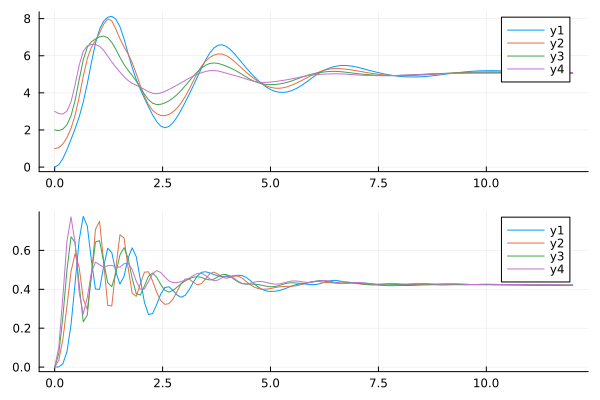

In [10]:
δ=0.1; #ωa=ωc+0.1
g=2;
η=1/5;
ωc = 2;
K=1/4;
γ=1/8;
ωl = 18.9 #9*ωa
H_drive = (ħ*ωc* a⁺*a) + (ħ*(ωc + δ)*σ⁺*σ) +  (ħ*g*(a*σ⁺ + a⁺*σ)) + ωl*η * (a⁺ + a);
J_d(γ, K) = [sqrt(γ)*σ, sqrt(2*K)*a];

ρ0d = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); # |n=0, g>
ρ1d = dm(basisstate(basis_fock, 2)⊗basisstate(basis_atom, 2)); # |n=1, g> 
ρ2d = dm(basisstate(basis_fock, 3)⊗basisstate(basis_atom, 2)); # |n=2, g> 
ρ3d = dm(basisstate(basis_fock, 4)⊗basisstate(basis_atom, 2)); # |n=3, g> 

t0d, ρ0td = timeevolution.master(T, ρ0d, H_drive, J_d(1/8, 1/4));
t1d, ρ1td = timeevolution.master(T, ρ1d, H_drive, J_d(1/8, 1/4));
t2d, ρ2td = timeevolution.master(T, ρ2d, H_drive, J_d(1/8, 1/4));
t3d, ρ3td = timeevolution.master(T, ρ3d, H_drive, J_d(1/8, 1/4));

p1d = plot(title="");
p1d = plot!(t0d, real.(expect(a⁺*a, ρ0td))); p1d = plot!(t1d, real.(expect(a⁺*a, ρ1td))); p1d = plot!(t2d, real.(expect(a⁺*a, ρ2td))); p1d = plot!(t3d, real.(expect(a⁺*a, ρ3td)));

p2d = plot(title="");
p2d = plot!(t0d, real.(expect(σ⁺*σ, ρ0td))); p2d = plot!(t1d, real.(expect(σ⁺*σ, ρ1td))); p2d = plot!(t2d, real.(expect(σ⁺*σ, ρ2td))); p2d = plot!(t3d, real.(expect(σ⁺*σ, ρ3td)));

plot(p1d, p2d, layout=(2,1))

# Task 4
 Vacuum Rabi splitting: Calculate stationary photon number (< a†a >) (i.e. photon number after sufficiently
long time) as function of the pump-atom detuning at resonance ω = ωa. Compare the case of weak coupling
g ≪κ≈γ and strong coupling g ≫ κ ≈ γ.

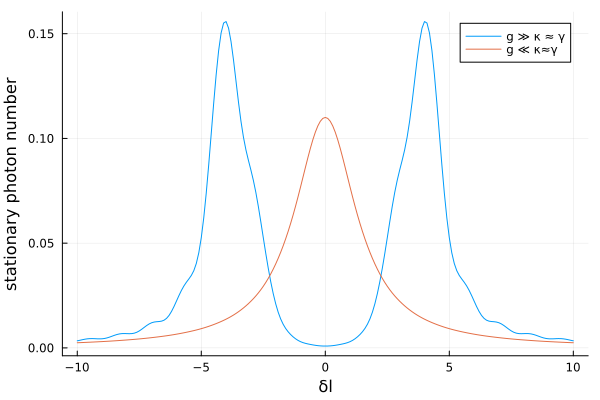

In [28]:
η=0.5;
K=2;
γ=2;
ωl = 1;
T = 0:0.1:5;

H_VRS(δl, g) = (ħ*δl*( a⁺*a + σ⁺*σ)) +  (ħ*g*(a*σ⁺ + a⁺*σ)) + ωl*η * (a⁺ + a);      ## at resonance: ωc = ωa -> δ=0; pump atom detuning: δl
J_d(γ, K) = [sqrt(γ)*σ, sqrt(K)*a];

delta_span = -10:0.1:10;
n_weak_stat = zeros(length(delta_span));
n_strong_stat = zeros(length(delta_span));

ρ0_VRS = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); # |n=0, g>

for (i, δl) in enumerate(delta_span)
    #weak
    t, ρ = timeevolution.master(T, ρ0_VRS, H_VRS(δl,0.1), J_d(3.0, 3.0));

    n_weak = real.(expect(a⁺*a, ρ));
    n_weak_stat[i] = n_weak[end];

    #strong
    t2, ρ2 = timeevolution.master(T, ρ0_VRS, H_VRS(δl,4.0), J_d(1.0, 1.0));

    n_strong = real.(expect(a⁺*a, ρ2));
    n_strong_stat[i] = n_strong[end];
end

plt1=plot(delta_span, n_strong_stat, xlabel="δl", ylabel="stationary photon number", label="g ≫ κ ≈ γ");
plt1=plot!(delta_span, n_weak_stat, label="g ≪ κ≈γ");

plot(plt1)

# Task 5
 Cavity anti-resonance: Calculate again the long time stationary photon number (a†a) as function of the
pump-atom detuning and compare the case of a narrow atomic resonance γ ≪ κ < g and a narrow cavity
κ ≪γ<g

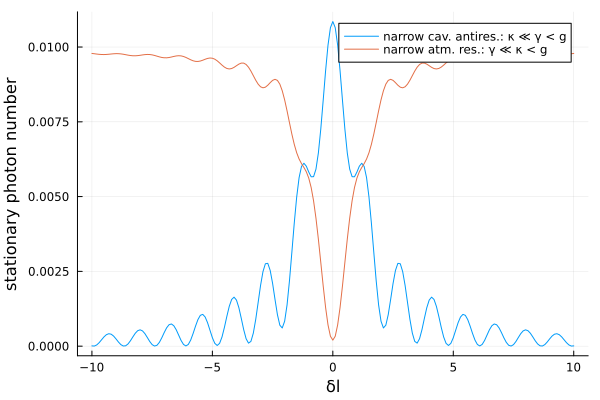

In [36]:
η=0.1;
K=2;
γ=2;
T = 0:0.1:5;

H_cav_antires(δc, δa, g) = ħ*δc*( a⁺*a ) + ħ*δa*(σ⁺*σ) +  (ħ*g*(a*σ⁺ + a⁺*σ)) + η * (a⁺ + a);      ## at resonance: ωc = ωa -> δ=0; we now add δa and δc to calculate


J_d(γ, K) = [sqrt(γ)*σ, sqrt(K)*a];

delta_span = -10:0.1:10;
n_narrow_at_stat = zeros(length(delta_span));
n_narrow_cav_stat = zeros(length(delta_span));

ρ0_VRS = dm(basisstate(basis_fock, 1)⊗basisstate(basis_atom, 2)); # |n=0, g>

for (i, δ) in enumerate(delta_span)
    #narrow atomic res
    t, ρ = timeevolution.master(T, ρ0_VRS, H_cav_antires(0, δ, 1), J_d(0.01, 2.0));

    n_narrow_at = real.(expect(a⁺*a, ρ));
    n_narrow_at_stat[i] = n_narrow_at[end];

    #narrow cavity res
    t2, ρ2 = timeevolution.master(T, ρ0_VRS, H_cav_antires(δ, 0, 1), J_d(2.0, 0.01));

    n_narrow_cav = real.(expect(a⁺*a, ρ2));
    n_narrow_cav_stat[i] = n_narrow_cav[end];
end

plt1=plot(delta_span, n_narrow_cav_stat, xlabel="δl", ylabel="stationary photon number", label="narrow cav. antires.: κ ≪ γ < g");
plt1=plot!(delta_span, n_narrow_at_stat, label="narrow atm. res.: γ ≪ κ < g ");

plot(plt1)